# 컨텍스트 관리와 오프로딩

**이 노트북에서 할 일**

1. 아주 긴 도구 결과가 파일로 옮겨지고 짧은 안내 글만 남는 것을 모델 없이 봅니다.
2. 옮기는 기준을 셈으로 확인하고, 한도를 바꾸면 무엇이 달라지는지 봅니다.
3. 실제 모델이 옮겨 둔 파일에서 필요한 줄을 다시 찾는 실행을 한 번 보고, 요청 수를 셉니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 6절에서 Deep Agent를 한 번 실행합니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때, 요청은 다섯 번 모두 3번이었습니다.
바깥 호출 한도 10과 서브에이전트 호출 한도 2를 주어, 요청이 끝없이 늘지 않게 막습니다.
요금표로 어림한 예상 비용은 0.01달러 아래이고, 청구 금액이 아닙니다.

옮겨 둔 결과는 상태 칸 `files`에만 두고, 디스크에는 파일을 쓰지 않습니다.
요약은 기준에 닿지 않아 일어나지 않고, 요약 요청도 나가지 않습니다.
모델의 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.
앞에서 배운 함수 넷은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 deepagents 0.7.0, langchain 1.4.0, langgraph 1.2.11입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
모델 없이 옮겨 두기의 기준과 모양을 보는 자리입니다.
5~7절은 실제 모델로 한 번 실행하는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 손으로 만든 요청 read_visit_log 호출 ID hand_log_1에서 노란 상자 도구 결과 88889자 기준 80000자를 넘음으로, 다시 회색 상자 FilesystemMiddleware 기준보다 크면 옮김으로 화살표가 갑니다. 거기서 나란한 두 칸으로 화살표가 갈라집니다. 왼쪽 칸 메시지 목록에는 노란 상자 도구 메시지 안내 글 1122자가 있습니다. 오른쪽 칸 상태 칸 files에는 노란 상자 /large_tool_results/hand_log_1 88889자 원래 결과와 같음 True가 있는 그림](attachment:05-1-긴-결과를-옮겨-두기.png)

위에서 아래로 읽습니다.
맨 위 초록 상자는 모델 없이 손으로 만든 요청이고, 노란 상자는 노트북 2·3절 출력입니다.
회색 상자는 설치판 소스로 확인한 판정 자리이고, 두 칸은 결과가 나뉘어 남은 서로 다른 자리라 나란히 두었습니다.
원래 결과는 상태 칸에 그대로 있고, 메시지 목록에는 짧은 안내 글만 남았습니다.
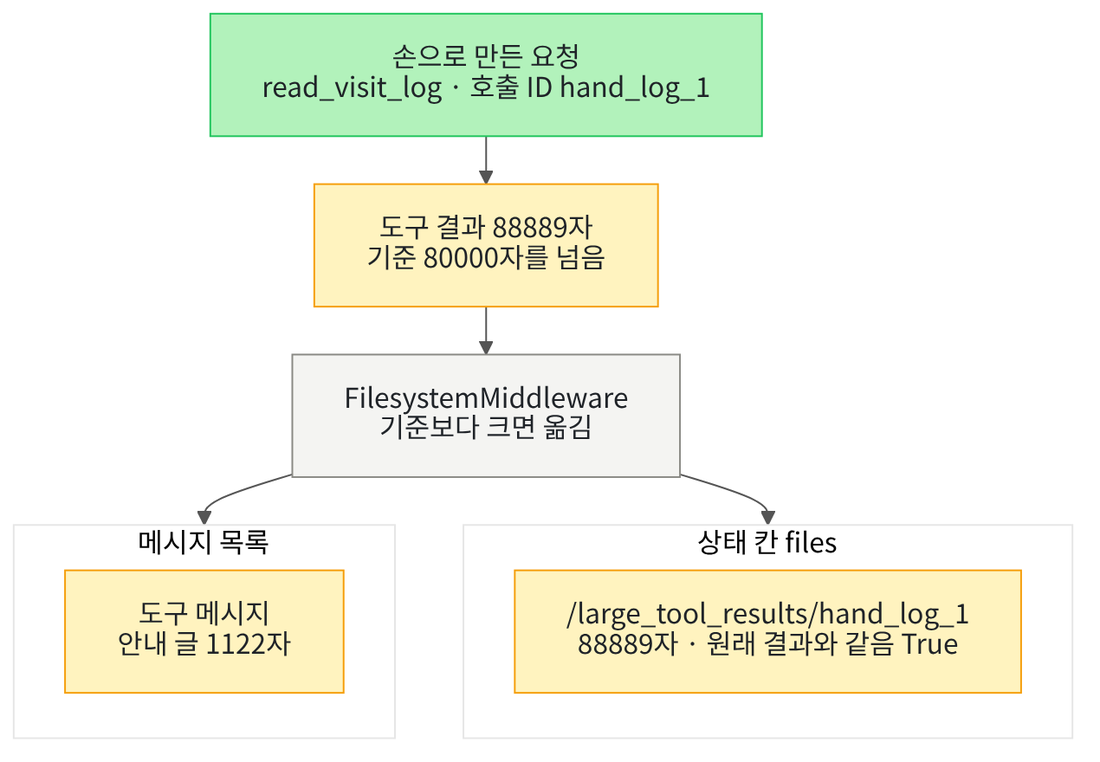

## 1. 준비

이 절에서는 아주 긴 도구 결과를 파일로 옮겨 두는 장치를 봅니다.
옮겨 두기(offloading)는 긴 도구 결과를 파일로 옮기고, 메시지 목록에는 짧은 글만 남기는 일입니다.
옮긴 뒤 남는 이 짧은 글을 아래 3절에서 안내 글이라고 부릅니다.
큰 짐은 창고에 넣고, 방에는 어디에 두었는지 적은 쪽지만 붙여 두는 것과 비슷합니다.
이 절 코드에서는 `FilesystemMiddleware`가 이 일을 맡고, 인자 `tool_token_limit_before_evict`가 기준을 정합니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langgraph: 1.2.11`이 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.
패키지 langgraph는 3절에서 작은 그래프를 직접 만들려고 설치 목록에 넣었습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상수 `NUM_CHARS_PER_TOKEN`은 이 절에서 처음 씁니다.
미들웨어 `FilesystemMiddleware`는 01절에서 인자 없이 만들어 보았고, 이 절에서는 인자를 주어 만듭니다.
마지막 가져오기 줄은 앞에서 배운 함수 넷을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·파일 미들웨어와 상태 형식(04절)·미들웨어(Ch 22)·모델·메시지·도구·그래프 이름을 가져옵니다
from deepagents import create_deep_agent
from deepagents.middleware.filesystem import FilesystemMiddleware, FilesystemState, NUM_CHARS_PER_TOKEN
from langchain.agents.middleware import ModelCallLimitMiddleware, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
# 앞 챕터와 01절에서 배운 함수 넷은 도구 파일에서 가져옵니다
from harness_tools import estimate_cost, sum_usage, tool_call_names, tool_names

print("도구 파일에서 가져온 함수:", "estimate_cost, sum_usage, tool_call_names, tool_names")

도구 파일에서 가져온 함수: estimate_cost, sum_usage, tool_call_names, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, sum_usage, tool_call_names, tool_names`가 보입니다.
네 함수의 뜻은 02절 1절에 적었습니다.
앞에서 배운 함수는 `harness_tools.py`에 모아 두었고, 파일을 열면 코드를 볼 수 있습니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 6절 실행 셀에서만 나갑니다.

2~4절은 이 객체로 Deep Agent를 만들기만 하고, 모델을 부르지 않습니다.
이 절은 파일을 디스크에 쓰지 않아, 04절의 임시 폴더 셀이 없습니다.
옮겨 둔 결과는 기본 백엔드의 상태 칸 `files`에만 생깁니다.

## 2. 긴 결과를 내놓는 도구

도구 결과가 짧으면 옮길 까닭이 없어서, 짧은 결과와 긴 결과를 함께 준비합니다.
짧은 결과는 02절의 규정 도구를 그대로 씁니다.
다음 셀은 02절 2절의 규정 글 셀과 같은 글입니다.

In [5]:
# 도구가 찾을 교재용 규정 글 넷을 주제어마다 정합니다(실제 도서관 규정이 아님)
library_rules = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "연장": "반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
}
print("규정 주제어:", list(library_rules))

규정 주제어: ['대출', '연장', '연체', '운영']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '연장', '연체', '운영']`이 보입니다.
02절과 같은 교재용 규정이고, 실제 도서관 규정이 아닙니다.

다음 셀도 02절의 도구 셀과 같은 글입니다.
맨 위 `@tool` 줄이 아래 함수를 도구로 등록하는 것도 02절과 같습니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_rule(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 연장, 연체, 운영 가운데 하나를 넣습니다."""
    # 없는 주제어면 오류 대신 정해 둔 안내 글을 내놓습니다
    if topic in library_rules:
        return library_rules[topic]
    return "그런 주제어의 규정은 없습니다. 대출, 연장, 연체, 운영 가운데 하나를 넣어 주세요."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 `lookup_rule`은 주제어 하나로 규정 글 하나를 찾습니다.
규정 글은 모두 한 줄짜리 짧은 글이라, 짧은 결과의 예로 씁니다.

긴 결과로는 자료실의 하루 방문 기록을 씁니다.
다음 셀은 기록의 줄 수와, 분실물 신고를 적을 자리와 그 줄의 글을 정합니다.
모두 교재용으로 정한 값입니다.

In [7]:
# 방문 기록 도구가 쓸 값을 정합니다(교재용 기록 — 줄 수, 분실물 기록을 둘 자리, 그 줄의 글)
log_line_count = 2000
lost_number = 345
lost_line = "방문 기록 " + str(lost_number) + ": 분실물 신고 — 파란 우산 1개를 안내 데스크에 맡김"
print("기록 줄 수:", log_line_count)
print("분실물 줄:", lost_line)

기록 줄 수: 2000
분실물 줄: 방문 기록 345: 분실물 신고 — 파란 우산 1개를 안내 데스크에 맡김


**결과 읽기** — 출력 줄 `기록 줄 수: 2000`이 보입니다.
라벨 `분실물 줄:` 뒤가 345번째 줄에 넣을 글입니다.
나머지 줄은 모두 같은 모양의 방문 기록입니다.

다음 셀은 방문 기록 전체를 한 글로 내놓는 도구를 만듭니다.
인자가 없는 도구라, 모델은 빈 인자로 부릅니다.
메서드 `join`은 Ch 16 03절처럼 글 목록을 사이 글로 이어 한 글로 만듭니다.
여기서는 사이 글이 줄바꿈 `"\n"`이라, 2,000줄짜리 글 하나가 됩니다.

In [8]:
# 방문 기록 전체를 한 글로 내놓는 도구를 만듭니다(맨 @tool 줄 — 02절 lookup_rule과 같은 모양)
@tool
def read_visit_log():
    """교육센터 자료실의 오늘 방문 기록 전체를 한 번에 내놓습니다."""
    visit_lines = []
    for number in range(1, log_line_count + 1):
        line = "방문 기록 " + str(number) + ": 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감"
        # 정해 둔 자리 한 줄만 분실물 기록으로 바꿉니다
        if number == lost_number:
            line = lost_line
        visit_lines.append(line)
    return "\n".join(visit_lines)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 설명에는 결과가 길다는 말을 적지 않았습니다.
모델은 도구를 부르기 전에는 결과의 길이를 모릅니다.

다음 셀은 모델 없이 이 도구만 실행해, 결과 글의 크기를 봅니다.
Ch 19 05절처럼 도구의 `invoke`에 인자 딕셔너리를 넘기고, 인자가 없어 빈 딕셔너리를 넘깁니다.
메서드 `splitlines`는 Ch 2 05절처럼 글을 줄마다 나눈 목록을 내놓습니다.

In [9]:
# 모델 없이 도구만 실행해, 결과 글의 줄 수·글자 수와 분실물 줄이 들어 있는지 봅니다(Ch 19 05절 도구.invoke)
visit_log_text = read_visit_log.invoke({})
visit_log_lines = visit_log_text.splitlines()
print("결과 줄 수:", len(visit_log_lines))
print("결과 글자 수:", len(visit_log_text))
print("분실물 줄이 들어 있는가:", lost_line in visit_log_text)
print("첫 줄:", visit_log_lines[0])

결과 줄 수: 2000
결과 글자 수: 88889
분실물 줄이 들어 있는가: True
첫 줄: 방문 기록 1: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감


**결과 읽기** — 출력 줄 `결과 줄 수: 2000`과 `결과 글자 수: 88889`가 보입니다.
출력 줄 `분실물 줄이 들어 있는가: True`로, 가운데쯤 한 줄만 분실물 기록인 것을 봅니다.
라벨 `첫 줄:` 뒤는 나머지 줄과 같은 모양의 기록입니다.

## 3. 기본 한도에서 옮겨 두기 보기

모델 없이 도구를 부르려고, 04절의 작은 그래프 함수를 다시 씁니다.
다음 셀은 04절 3절 셀과 같은 글입니다.
Deep Agent 하나를 받아, 도구 실행 노드만 든 작은 그래프를 내놓습니다.

In [10]:
# Deep Agent 하나를 받아, 그 도구 실행 노드 하나만 든 작은 그래프를 만들어 내놓습니다(상태 형식은 files 칸이 있는 FilesystemState)
def tools_only_graph(agent):
    builder = StateGraph(FilesystemState)
    builder.add_node("tools", agent.nodes["tools"].bound)
    builder.add_edge(START, "tools")
    builder.add_edge("tools", END)
    return builder.compile()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 실행 노드에는 `FilesystemMiddleware`의 감싸기형 훅 `wrap_tool_call`이 함께 붙어 있습니다.
그래서 이 작은 그래프로 도구를 불러도, 옮겨 두기가 그대로 일합니다.

다음 셀은 두 도구만 넘겨 Deep Agent를 만들고, 작은 그래프도 만듭니다.
한도를 바꾸는 인자가 없어, 옮기는 한도는 기본값 그대로입니다.

In [11]:
# 한도를 바꾸지 않은 Deep Agent에 두 도구를 넘기고, 도구 실행 노드만 든 작은 그래프를 만듭니다(요청은 보내지 않음)
base_agent = create_deep_agent(model=model, tools=[lookup_rule, read_visit_log])
base_tools = tool_names(base_agent)
print("그래프에 등록된 도구 수:", len(base_tools))
base_tools_graph = tools_only_graph(base_agent)

그래프에 등록된 도구 수: 11


**결과 읽기** — 출력 줄 `그래프에 등록된 도구 수: 11`이 보입니다.
기본 도구 아홉에 우리 도구 둘을 더한 수입니다.

다음 셀은 모델 없이 `lookup_rule` 요청 둘을 담은 응답을 손으로 만듭니다.
04절 3절처럼 칸 `name`·`args`·`id`·`type`을 적은 딕셔너리를 넣습니다.
주제어는 대출과 운영이고, 두 규정 글의 길이는 4절에서 다시 씁니다.

In [12]:
# 모델 없이, lookup_rule 요청 둘을 담은 응답을 손으로 만듭니다(04절 3절 모양)
loan_call = {"name": "lookup_rule", "args": {"topic": "대출"}, "id": "hand_rule_1", "type": "tool_call"}
hours_call = {"name": "lookup_rule", "args": {"topic": "운영"}, "id": "hand_rule_2", "type": "tool_call"}
rule_request = AIMessage(content="", tool_calls=[loan_call, hours_call])
print("요청한 도구:", tool_call_names(rule_request))

요청한 도구: ['lookup_rule', 'lookup_rule']


**결과 읽기** — 출력 줄 `요청한 도구: ['lookup_rule', 'lookup_rule']`이 보입니다.
응답 하나에 도구 요청 둘을 담았습니다.

호출 ID `hand_rule_1`과 `hand_rule_2`는 우리가 정한 값입니다.
다음 셀은 이 요청을 작은 그래프에 넣고, 도구 메시지마다 글과 글자 수를 봅니다.
자르기 `[1:]`로 결과 메시지 목록의 맨 앞 손 요청은 빼고 봅니다.
실행 전에 예상해 봅니다.
짧은 결과라면 도구 메시지에 규정 글이 그대로 남을 것입니다.

In [13]:
# 기본 한도의 작은 그래프에 넣고, 도구 메시지마다 글과 글자 수, 상태 칸 files를 봅니다
rule_result = base_tools_graph.invoke({"messages": [rule_request]})
for message in rule_result["messages"][1:]:
    print("도구 메시지:", message.content, "| 글자 수:", len(message.content))
print("상태 칸 files의 파일 위치:", list(rule_result["files"]))

도구 메시지: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다. | 글자 수: 33
도구 메시지: 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다. | 글자 수: 41
상태 칸 files의 파일 위치: []


**결과 읽기** — 두 도구 메시지에 규정 글이 그대로 남았고, 줄 끝이 `글자 수: 33`과 `글자 수: 41`입니다.
출력 줄 `상태 칸 files의 파일 위치: []`에서, 옮겨 둔 파일은 없습니다.
결과 메시지 목록의 맨 앞 손 요청은 빼고, 도구 메시지만 보았습니다.

다음 셀은 방문 기록 도구 요청 하나를 담은 응답을 손으로 만듭니다.
호출 ID는 `hand_log_1`로 정해, 옮겨 둔 파일 이름도 미리 정해지게 했습니다.

In [14]:
# 모델 없이, 방문 기록 도구 요청 하나를 담은 응답을 손으로 만듭니다(호출 ID도 우리가 정함)
log_call = {"name": "read_visit_log", "args": {}, "id": "hand_log_1", "type": "tool_call"}
log_request = AIMessage(content="", tool_calls=[log_call])
print("요청한 도구:", tool_call_names(log_request))

요청한 도구: ['read_visit_log']


**결과 읽기** — 출력 줄 `요청한 도구: ['read_visit_log']`가 보입니다.

다음 셀은 이 요청을 같은 작은 그래프에 넣습니다.
실행 전에 예상해 봅니다.
방문 기록은 규정 글보다 훨씬 길어, 도구 메시지가 원래 결과와 달라질 것입니다.

In [15]:
# 같은 작은 그래프에 넣고, 원래 결과와 도구 메시지의 글자 수, 상태 칸 files를 봅니다
log_result = base_tools_graph.invoke({"messages": [log_request]})
log_message = log_result["messages"][-1]
print("원래 결과 글자 수:", len(visit_log_text))
print("도구 메시지 글자 수:", len(log_message.content))
print("상태 칸 files의 파일 위치:", list(log_result["files"]))

원래 결과 글자 수: 88889
도구 메시지 글자 수: 1122
상태 칸 files의 파일 위치: ['/large_tool_results/hand_log_1']


**결과 읽기** — 출력 줄 `원래 결과 글자 수: 88889`와 `도구 메시지 글자 수: 1122`가 보입니다.
출력 줄 `상태 칸 files의 파일 위치: ['/large_tool_results/hand_log_1']`에서, 파일 하나가 생겼습니다.
파일 이름은 우리가 정한 호출 ID 그대로입니다.
도구가 내놓은 글이 메시지 목록에 들어가기 전에 파일로 옮겨지고, 짧은 글로 바뀌었습니다.

다음 셀은 도구 메시지에 남은 짧은 글을 그대로 봅니다.
여러 줄이라 라벨 줄을 따로 출력합니다.

In [16]:
# 도구 메시지에 남은 짧은 글을 그대로 봅니다(여러 줄이라 라벨 줄을 따로 출력)
print("도구 메시지:")
print(log_message.content)

도구 메시지:
Tool result too large, the result of this tool call hand_log_1 was saved in the filesystem at this path: /large_tool_results/hand_log_1

You can read the result from the filesystem by using the read_file tool, but make sure to only read part of the result at a time.

You can do this by specifying an offset and limit in the read_file tool call. For example, to read the first 100 lines, you can use the read_file tool with offset=0 and limit=100.

Here is a preview showing the head and tail of the result (lines of the form `... [N lines truncated] ...` indicate omitted lines in the middle of the content):

1  방문 기록 1: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감
2  방문 기록 2: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감
3  방문 기록 3: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감
4  방문 기록 4: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감
5  방문 기록 5: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감
... [1990 lines truncated] ...
1996  방문 기록 1996: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감
1997  방문 기록 1997: 열람실에서 신문과 잡지, 새로 들어온 책 목록을 읽고 나감
1998  방문 기록 1998: 열람실에서

**결과 읽기** — 라벨 줄 아래 첫 줄은 결과가 너무 커서 파일에 두었다는 말과 파일 위치입니다.
그다음 두 단락은 `read_file`로 조금씩 나눠 읽으라는 안내입니다.
맨 아래는 결과의 앞 다섯 줄과 뒤 다섯 줄이고, 가운데 줄 `... [1990 lines truncated] ...`는 뺀 줄 수입니다.
이 절에서는 이 짧은 글 전체를 안내 글이라고 부르겠습니다.

345번째 분실물 줄은 안내 글에 없습니다.
모델이 분실물을 찾으려면, 옮겨 둔 파일을 파일 도구로 다시 봐야 합니다.
설치판 `middleware/_message_eviction.py` 37~63행에서, 미리보기는 결과가 열 줄을 넘으면 앞뒤 다섯 줄입니다.
50~53행에서, 결과가 열 줄 이하이면 모든 줄을 붙입니다.

도구 `lookup_rule`의 주석에 있는 「정해 둔 안내 글」은 이 안내 글과 다릅니다.
없는 주제어에 도구가 내놓는, 정해 둔 글을 가리킵니다.

In [17]:
# 상태 칸 files에 옮겨 둔 파일의 글이 원래 결과와 같은지 봅니다
saved_entry = log_result["files"]["/large_tool_results/hand_log_1"]
print("옮겨 둔 글자 수:", len(saved_entry["content"]))
print("원래 결과와 같은가:", saved_entry["content"] == visit_log_text)

옮겨 둔 글자 수: 88889
원래 결과와 같은가: True


**결과 읽기** — 출력 줄 `옮겨 둔 글자 수: 88889`와 `원래 결과와 같은가: True`가 보입니다.
원래 결과는 한 글자도 줄지 않고 상태 칸 `files`에 그대로 있습니다.
옮겨 두기는 요약처럼 글을 다시 쓰지 않고, 메시지 목록의 글만 안내 글로 바꿉니다.

그러면 어떤 결과를 옮길까요?
설치판 `middleware/filesystem.py` 2846행은 결과 글자 수가 「4 × 한도」 이하이면 그대로 둡니다.
그보다 크면 옮깁니다.
다음 셀은 이 기준을 기본 한도로 셉니다.

In [18]:
# 옮기는 기준을 기본 한도로 셉니다(기본 한도 20000은 설치판 소스의 기본값, 4는 라이브러리 상수)
default_limit = 20000
default_threshold = NUM_CHARS_PER_TOKEN * default_limit
print("기본 한도(토큰):", default_limit)
print("한 토큰으로 어림하는 글자 수:", NUM_CHARS_PER_TOKEN)
print("기본 기준(글자):", default_threshold)
print("운영 규정이 기준을 넘는가:", len(library_rules["운영"]) > default_threshold)
print("방문 기록이 기준을 넘는가:", len(visit_log_text) > default_threshold)

기본 한도(토큰): 20000
한 토큰으로 어림하는 글자 수: 4
기본 기준(글자): 80000
운영 규정이 기준을 넘는가: False
방문 기록이 기준을 넘는가: True


**결과 읽기** — 출력 줄 `기본 한도(토큰): 20000`과 `기본 기준(글자): 80000`이 보입니다.
운영 규정은 기준을 넘지 않고, 방문 기록은 넘습니다.
그래서 앞 셀들에서 규정 글은 그대로 남고, 방문 기록만 옮겨졌습니다.

인자 이름에는 토큰이 들어 있지만, 실제 판정은 글자 수로 합니다.
설치판 주석은 한 토큰을 네 글자로 어림한다고 적습니다.
이 절은 결과 글의 토큰 수를 세지 않았습니다.

## 4. 한도를 바꿔 보기와 요약 기준

### 값 바꿔 보기: 같은 이름 미들웨어로 한도 낮추기

한도를 바꾸려면 `FilesystemMiddleware`를 새로 만들어 인자 `middleware=`에 넣습니다.
설치판 `graph.py` 201~235행에서, 기본 미들웨어와 이름이 같은 것은 그 자리를 바꿉니다.
바꿀 값은 한도 하나이고, 기준이 40자가 되게 10으로 둡니다.
실행 전에 예상해 봅니다.
33자인 대출 규정은 그대로, 41자인 운영 규정은 옮겨질 것입니다.

In [19]:
# 값 바꿔 보기: 한도 10인 FilesystemMiddleware를 middleware=에 넣어, 같은 이름의 기본 자리를 바꿉니다(요청은 보내지 않음)
small_token_limit = 10
small_limit = FilesystemMiddleware(tool_token_limit_before_evict=small_token_limit)
small_agent = create_deep_agent(model=model, tools=[lookup_rule, read_visit_log], middleware=[small_limit])
print("작은 한도(토큰):", small_token_limit)
print("작은 기준(글자):", NUM_CHARS_PER_TOKEN * small_token_limit)
print("도구 이름이 같은가:", tool_names(small_agent) == base_tools)
small_tools_graph = tools_only_graph(small_agent)

작은 한도(토큰): 10
작은 기준(글자): 40
도구 이름이 같은가: True


**결과 읽기** — 출력 줄 `작은 기준(글자): 40`과 `도구 이름이 같은가: True`가 보입니다.
미들웨어를 하나 더 붙인 것이 아니라 기본 자리를 바꿔서, 도구 이름이 그대로입니다.

다음 셀은 3절의 규정 요청 둘을 이 작은 그래프에 그대로 넣습니다.
도구 메시지마다 호출 ID와 글자 수, 상태 칸 `files`를 봅니다.

In [20]:
# 같은 규정 요청 둘을 한도 10의 작은 그래프에 넣고, 도구 메시지마다 호출 ID·글자 수와 상태 칸 files를 봅니다
small_result = small_tools_graph.invoke({"messages": [rule_request]})
for message in small_result["messages"][1:]:
    print("호출 ID:", message.tool_call_id, "| 글자 수:", len(message.content))
print("상태 칸 files의 파일 위치:", list(small_result["files"]))

호출 ID: hand_rule_1 | 글자 수: 33
호출 ID: hand_rule_2 | 글자 수: 658
상태 칸 files의 파일 위치: ['/large_tool_results/hand_rule_2']


**결과 읽기** — 출력 줄 `호출 ID: hand_rule_1 | 글자 수: 33`에서, 대출 규정은 그대로 남았습니다.
출력 줄 `호출 ID: hand_rule_2 | 글자 수: 658`에서, 운영 규정은 안내 글로 바뀌었습니다.
출력 줄 `상태 칸 files의 파일 위치: ['/large_tool_results/hand_rule_2']`도 보입니다.
41자 결과가 기준을 한 글자 넘어 옮겨졌고, 안내 글은 원래 글보다 훨씬 깁니다.

안내 글에는 늘 같은 설명 단락과 파일 위치, 앞뒤 미리보기가 붙습니다.
그래서 옮겨 두기는 결과가 충분히 클 때만 메시지 목록을 줄입니다.
이 셀의 한도 10은 옮겨지는 모양을 짧은 글로 보여 주려고 정한 값입니다.

### 요약은 켜지지 않습니다

01절에서 본 기본 미들웨어 다섯에는 요약 미들웨어도 있습니다.
요약은 긴 대화의 앞부분을, 모델이 쓴 요약 글로 바꿔 요청에 싣는 장치입니다.
설치판 `middleware/summarization.py` 249~286행에서, 모델 정보에 입력 한도가 있으면 그 85%를 기준으로 씁니다.
모델 객체의 속성 `profile`은 입력 한도 같은 모델 정보를 담은 딕셔너리입니다.
다음 셀은 모델 요청 없이 이 기준을 셉니다.

In [21]:
# 요약이 켜지는 기준을 모델 객체의 정보(profile)로 셉니다(요약은 실행하지 않음 — 모델 요청 없음)
max_input_tokens = model.profile["max_input_tokens"]
summary_fraction = 0.85
summary_threshold = int(max_input_tokens * summary_fraction)
print("모델이 받을 수 있는 입력 토큰:", max_input_tokens)
print("요약이 켜지는 기준(토큰):", summary_threshold)

모델이 받을 수 있는 입력 토큰: 400000
요약이 켜지는 기준(토큰): 340000


**결과 읽기** — 출력 줄 `모델이 받을 수 있는 입력 토큰: 400000`과 `요약이 켜지는 기준(토큰): 340000`이 보입니다.
요약은 요청에 실린 메시지의 토큰 수가 기준 이상일 때 시작합니다.
이 절의 요청은 그보다 훨씬 작아, 이 노트북에서 요약은 일어나지 않습니다.
요약 글을 쓰는 모델 요청도 나가지 않습니다.
요약을 켜 보려면 같은 이름 요약 미들웨어에 작은 기준을 주어야 하고, 이 노트북에서는 실행하지 않았습니다.

## 5. 실제 모델을 부를 준비

6절에서는 기본 한도 그대로의 Deep Agent에 방문 기록 도구를 주고, 분실물 기록을 찾게 합니다.
다음 셀은 03절 셀과 같은 글의 바깥 호출 한도입니다.

In [22]:
# 바깥 에이전트의 모델 요청을 열 번까지로 막는 호출 한도를 만듭니다(02절 셀과 한도만 다름)
outer_limit = ModelCallLimitMiddleware(run_limit=10, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 10


**결과 읽기** — 출력 줄 `바깥 호출 한도: 10`이 보입니다.
주석의 「02절 셀과 한도만 다름」은 이 셀을 처음 쓴 03절에서 적은 말입니다.
방문 기록을 부르고, 옮겨 둔 파일을 찾고, 답하는 흐름이라 10이면 넉넉합니다.

다음 셀은 02절과 같은 글의 general-purpose 명세이고, 자기 호출 한도는 2입니다.
01절에서 본 것처럼 바깥 호출 한도는 이 서브에이전트로 옮겨 가지 않아, 두 곳에 따로 줍니다.

In [23]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도 둘을 넣습니다(01절 6절 모양)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
한 번 실행의 모델 요청은 10에, 도구 `task`를 부른 횟수 × 2를 더한 값을 넘지 않습니다.

다음 셀은 이 절에서 새로 만드는 기록 훅입니다.
모델 요청이 나갈 때마다, 요청에 실린 메시지 글의 글자 수를 모두 더해 기록 목록 `seen_sizes`에 붙입니다.
02절 기록 훅과 모양은 같고, 적는 값만 다릅니다.
속성 `text`는 메시지의 글이고, 도구 요청만 든 응답은 빈 글입니다.

In [24]:
# 모델 요청이 나갈 때마다, 그 요청에 실린 메시지 글의 글자 수 합을 기록 목록에 붙이는 훅입니다(Ch 22 02절 기록 훅 모양)
@wrap_model_call
def record_sizes(request, handler):
    total = 0
    for message in request.messages:
        total = total + len(message.text)
    seen_sizes.append(total)
    # 기록만 하고, 요청은 그대로 모델에게 보냅니다
    return handler(request)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
시스템 메시지 글과 도구 요청 인자는 세지 않습니다.
방문 기록 전체가 어느 요청에 실린다면, 그 요청의 합은 방문 기록 글자 수보다 커집니다.
이 훅도 바깥 인자 `middleware=`에만 넣어, general-purpose의 요청은 적지 않습니다.

## 6. 옮겨 둔 결과를 모델이 다시 찾는 실행

다음 셀은 방문 기록 도구와 5절의 부품을 넘겨 Deep Agent를 만듭니다.
한도를 바꾸는 미들웨어는 넣지 않아, 옮기는 기준은 기본 80,000자입니다.

In [25]:
# 기본 한도 그대로의 Deep Agent에 방문 기록 도구·호출 한도·기록 훅·명세를 넘깁니다(요청은 아직 보내지 않음)
run_agent = create_deep_agent(
    model=model,
    tools=[read_visit_log],
    middleware=[outer_limit, record_sizes],
    subagents=[helper_spec],
)
run_tools = tool_names(run_agent)
print("그래프에 등록된 도구 수:", len(run_tools))

그래프에 등록된 도구 수: 10


**결과 읽기** — 출력 줄 `그래프에 등록된 도구 수: 10`이 보입니다.
기본 도구 아홉과 방문 기록 도구 하나입니다.

질문은 방문 기록을 불러 분실물 신고 기록을 찾고, 한 문장으로 답하라는 글입니다.
어떤 파일 도구를 쓰라고는 적지 않았습니다.
실행 전에 예상해 봅니다.
방문 기록은 옮겨지고, 모델은 안내 글만 보고 파일에서 분실물 줄을 찾아야 할 것입니다.

In [26]:
# 기록 목록을 새로 만들고, 방문 기록에서 분실물 기록을 찾아 달라는 질문 한 줄로 한 번 실행합니다
seen_sizes = []
question = "교육센터 자료실의 오늘 방문 기록을 불러와서, 분실물 신고가 적힌 기록을 찾아 주세요. 무엇을 어디에 맡겼는지 한 문장으로 답해 주세요."
first_input = {"messages": [HumanMessage(content=question)]}
input_count = len(first_input["messages"])
run_result = run_agent.invoke(first_input)
run_messages = run_result["messages"]
print("결과 메시지 수:", len(run_messages))

결과 메시지 수: 6


**결과 읽기** — 라벨 `결과 메시지 수:` 뒤에 이번 실행의 메시지 수가 보입니다.
넣은 질문 하나 뒤에 모델 응답과 도구 메시지가 더해졌습니다.

이번 실행에서는 `결과 메시지 수: 6`이었습니다.
모델이 파일 도구를 몇 번 부르는지에 따라 달라지는 값입니다.
노트북 밖 다섯 번과 새 커널 두 번에서는 모두 여섯이었습니다.

다음 셀은 이번 실행이 더한 메시지를 차례로 봅니다.
도구 메시지 글에는 서비스가 정한 호출 ID가 들어 있어, 글 대신 도구 이름과 글자 수만 출력합니다.

In [27]:
# 이번 실행이 더한 메시지마다 종류와 도구 이름을 보고, 도구 메시지는 글자 수와 안내 글인지만 봅니다(호출 ID는 출력하지 않음)
run_new = run_messages[input_count:]
print("이번 실행이 더한 메시지:")
for message in run_new:
    kind = type(message).__name__
    if kind == "AIMessage":
        print(kind, "| 도구 호출 요청:", tool_call_names(message))
    if kind == "ToolMessage":
        is_notice = message.content.startswith("Tool result too large")
        print(kind, "|", message.name, "| 글자 수:", len(message.content), "| 안내 글인가:", is_notice)
print("마지막 답:", run_messages[-1].text)

이번 실행이 더한 메시지:
AIMessage | 도구 호출 요청: ['read_visit_log']
ToolMessage | read_visit_log | 글자 수: 1160 | 안내 글인가: True
AIMessage | 도구 호출 요청: ['grep']
ToolMessage | grep | 글자 수: 98 | 안내 글인가: False
AIMessage | 도구 호출 요청: []
마지막 답: 파란 우산 1개를 안내 데스크에 맡겼습니다.


**결과 읽기** — 라벨 줄 아래 첫 줄 `AIMessage | 도구 호출 요청: ['read_visit_log']`가 첫 응답입니다.
바로 아래 `read_visit_log` 도구 메시지 줄은 `안내 글인가: True`입니다.
모델이 받은 것은 방문 기록 전체가 아니라, 3절에서 본 모양의 안내 글입니다.
라벨 `마지막 답:` 앞 줄은 도구 요청이 없는 응답이고, 그 글이 마지막 답입니다.

이번 실행에서 모델은 둘째 응답에서 `grep`을 한 번 요청했고, 그 결과를 받은 뒤 답했습니다.
노트북 밖 다섯 번과 새 커널 두 번에서 모두 방문 기록 도구, `grep`, 답의 차례였습니다.
어느 파일 도구를 어떤 인자로 부를지는 모델이 정하는 값이라, 실행마다 달라질 수 있습니다.
안내 글에는 호출 ID가 두 번 들어가, 이번 `글자 수: 1160`은 3절의 1122와 호출 ID 길이만큼 다릅니다.
마지막 답 글도 모델이 쓴 글이라 실행마다 달라질 수 있습니다.

다음 셀은 결과의 상태 칸 `files`에서 옮겨 둔 파일을 봅니다.

In [28]:
# 상태 칸 files에서 /large_tool_results/ 아래 파일을 세고, 그 글이 방문 기록 전체와 같은지 봅니다(파일 이름은 출력하지 않음)
offloaded = []
for file_path in run_result["files"]:
    if file_path.startswith("/large_tool_results/"):
        offloaded.append(file_path)
print("옮겨 둔 파일 수:", len(offloaded))
for file_path in offloaded:
    print("방문 기록 전체와 같은가:", run_result["files"][file_path]["content"] == visit_log_text)

옮겨 둔 파일 수: 1
방문 기록 전체와 같은가: True


**결과 읽기** — 출력 줄 `옮겨 둔 파일 수: 1`과 `방문 기록 전체와 같은가: True`가 보입니다.
3절처럼, 옮겨 둔 파일은 상태 칸 `files`의 `/large_tool_results/` 아래에 생겼습니다.
파일 이름은 서비스가 정한 호출 ID라 실행마다 달라, 출력하지 않았습니다.
기본 백엔드라 디스크에는 아무 파일도 쓰지 않았습니다.

다음 셀은 기록 훅이 적은 값을 봅니다.
요청마다 모델이 받은 메시지 글자 수 합이, 방문 기록 글자 수보다 모두 작은지 확인합니다.

In [29]:
# 기록 훅이 적은 요청마다의 글자 수 합을 보고, 모두 방문 기록 글자 수보다 작은지 봅니다
print("요청마다 받은 메시지 글자 수:", seen_sizes)
all_smaller = True
for size in seen_sizes:
    if size >= len(visit_log_text):
        all_smaller = False
print("모두 방문 기록보다 작은가:", all_smaller)

요청마다 받은 메시지 글자 수: [76, 1236, 1334]
모두 방문 기록보다 작은가: True


**결과 읽기** — 출력 줄 `모두 방문 기록보다 작은가: True`가 보입니다.
방문 기록 전체는 어느 요청에도 실리지 않았습니다.
모델은 안내 글과, 파일 도구로 찾은 결과만 받았습니다.

이번 실행에서는 `요청마다 받은 메시지 글자 수: [76, 1236, 1334]`였습니다.
첫 요청은 질문 한 줄이고, 둘째 요청부터 안내 글과 파일 도구 결과가 더해졌습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같은 목록이었습니다.
다만 호출 ID 길이와 파일 도구 결과에 따라 달라질 수 있는 값입니다.

## 7. 요청 수와 예상 비용

이번 실행에서는 도구 `task`를 부르지 않아, 모델 요청은 모두 바깥 에이전트의 것입니다.
02절처럼 응답으로 센 요청 수와 기록 훅이 센 요청 수를 견줍니다.

In [30]:
# 이번 실행이 더한 메시지만 Ch 19 05절 함수 sum_usage로 세고, 기록 훅이 센 요청 수와 견줍니다
run_usage = sum_usage(run_new)
print("응답으로 센 요청 수:", run_usage["requests"])
print("기록 훅이 센 요청 수:", len(seen_sizes))
print("입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])

응답으로 센 요청 수: 3
기록 훅이 센 요청 수: 3
입력 토큰: 6702 | 출력 토큰: 86


**결과 읽기** — 라벨 `응답으로 센 요청 수:`와 `기록 훅이 센 요청 수:` 뒤의 수가 같습니다.
요청 수는 도구를 요청한 응답 수에 마지막 응답 하나를 더한 값입니다.

이번 실행에서는 요청 3번, `입력 토큰: 6702 | 출력 토큰: 86`이었습니다.
6절 출력에서 도구 요청이 든 응답 줄이 둘이라, 셈으로도 3번입니다.
노트북 밖 다섯 번과 새 커널 두 번에서 요청은 모두 3번이었습니다.
입력·출력 토큰은 새 커널 두 번과 노트북 밖 다섯 번에서 조금씩 달랐습니다.

다음 셀은 02절과 같은 글의 셀로, 이번 실행의 예상 비용을 셉니다.
요금은 과정 요금표(2026-09-17)의 100만 토큰당 달러이고, 예상 비용은 청구 금액이 아닙니다.

In [31]:
# 2026-09-17 요금표(100만 토큰당 달러)로 이번 실행의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
run_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(run_cost, 6)
print("예상 비용(달러):", rounded_cost)

예상 비용(달러): 0.005413


**결과 읽기** — 라벨 `예상 비용(달러):` 뒤에 이번 실행의 어림값이 보입니다.
토큰 수가 실행마다 달라, 이 값도 달라질 수 있습니다.
합친 사용량에는 캐시 입력 칸이 없어, 입력 토큰을 모두 입력 요금으로 셉니다.

이번 실행에서는 `예상 비용(달러): 0.005413`이었습니다.
노트북 밖 다섯 번에서는 0.005396에서 0.005413 사이였습니다.
캐시 입력을 빼지 않은 어림이라, 청구 금액은 이보다 작을 수 있습니다.

## 정리

1. 도구 결과가 「4 × 한도」자를 넘으면, 원래 결과는 상태 칸 `files`로 옮겨지고 도구 메시지에는 안내 글만 남습니다.
2. 같은 이름 미들웨어로 한도를 바꾸면 기본 자리가 바뀌고, 작은 결과는 안내 글이 원래보다 길어질 수 있습니다.
3. 모델은 안내 글만 받으므로, 미리보기에 없는 줄은 파일 도구로 다시 찾아야 합니다.

06절에서는 일을 서브에이전트에게 맡기는 장면을 봅니다.
서브에이전트가 상태 칸 `files`를 함께 쓰는 모양도 봅니다.